In [3]:
print('hello')

hello


In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("clean.csv")

target = "bad_flg_90plus_24m"
leaky = ["consumer_bad_flg_90plus_24m", "bal_12m", "bal_24m", "line_12m", "line_24m"]
drop_scores = ["Score1", "Score2", "Score2_nodata"]

X = pd.get_dummies(df.drop(columns=[target] + leaky + drop_scores),
                   columns=["Acct12"], dtype=int)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape)    # should be (239170, 56)

(239170, 56)


In [2]:
cols = ["Util3", "Acct7", "Del1", "Col1", "Acct1", "line_12m", "bad_flg_90plus_24m"]
print(df[["Score1", "Score2"] + cols].corr(method="spearman").loc[["Score1", "Score2"]].round(2))

        Score1  Score2  Util3  Acct7  Del1  Col1  Acct1  line_12m  \
Score1    1.00    0.93  -0.67   0.63 -0.57 -0.49   0.55      0.71   
Score2    0.93    1.00  -0.70   0.69 -0.65 -0.53   0.49      0.69   

        bad_flg_90plus_24m  
Score1               -0.29  
Score2               -0.29  


# Building Linear Regression Model

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

logreg = make_pipeline(SimpleImputer(strategy="median"),
                       StandardScaler(),
                       LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

prob_lr = logreg.predict_proba(X_test)[:, 1]
print("Logistic AUC:", roc_auc_score(y_test, prob_lr))

Logistic AUC: 0.8525545704941224


# Building Random Forest Model

In [4]:
from sklearn.ensemble import RandomForestClassifier

rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestClassifier(n_estimators=200, min_samples_leaf=50,
                                          n_jobs=-1, random_state=42))
rf.fit(X_train, y_train)

prob_rf = rf.predict_proba(X_test)[:, 1]
print("Random forest AUC:", roc_auc_score(y_test, prob_rf))

Random forest AUC: 0.8578335604993729


In [5]:
results = pd.DataFrame({
    "actual_default": y_test.values,
    "risk_score_logistic": (prob_lr * 100).round(1),
    "risk_score_forest": (prob_rf * 100).round(1),
})
results.head(10)

,actual_default,risk_score_logistic,risk_score_forest
0,0,6.5,4.2
1,0,1.4,2.6
2,0,25.6,23.1
3,1,17.2,19.6
4,0,11.2,7.7
5,0,15.9,14.9
6,0,1.8,2.2
7,0,3.1,3.8
8,0,0.6,0.4
9,0,5.2,3.3


# Above: Using model to see if someone defaulted comparing to our risk scores from the models 

# Below: Testing whether the scores can be trusted through making 10 equal groups from safest to riskiest

In [6]:
results["group"] = pd.qcut(results["risk_score_forest"], 10, duplicates="drop")
print(results.groupby("group", observed=True)
             .agg(avg_score=("risk_score_forest", "mean"),
                  actual_default_pct=("actual_default", lambda s: s.mean() * 100)))

               avg_score  actual_default_pct
group                                       
(-0.001, 0.3]   0.200918            0.181019
(0.3, 0.6]      0.489525            0.333704
(0.6, 1.0]      0.841627            0.411946
(1.0, 1.8]      1.422418            1.101760
(1.8, 2.8]      2.322197            1.614699
(2.8, 4.4]      3.580849            2.742895
(4.4, 6.9]      5.582325            4.841682
(6.9, 10.9]     8.731469            7.799865
(10.9, 17.9]   14.130085           13.849491
(17.9, 57.2]   25.608994           30.048846


# Below: Finding what was important inside the random forest model

In [7]:
importance = pd.Series(rf[-1].feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(10))

Acct7    0.117508
Util3    0.108425
Acct1    0.102529
Col1     0.087861
Inq1     0.063214
Del1     0.059540
Acct5    0.052340
Del4     0.051874
Util1    0.039689
CO1      0.039229
dtype: float64


Below: Finding what was important inside the logistic regression model

In [8]:
coefs = pd.Series(logreg[-1].coef_[0], index=X.columns)

top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
print(top)

Acct10         -0.536644
Util3           0.470165
Acct1          -0.297488
Inq1            0.294360
Acct7          -0.277800
Acct2           0.264543
Acct3          -0.228353
Util3_nodata    0.202554
Acct12_NU      -0.129174
Acct4           0.124440
dtype: float64


# Determining what Interest Rate and Loss Rate to pick

In [9]:
import numpy as np

cutoff_%                9.00
approved_%             76.10
default_rate_%          2.01
profit            7111579.00
Name: 7, dtype: float64
Profit if you approve everyone: 6270130


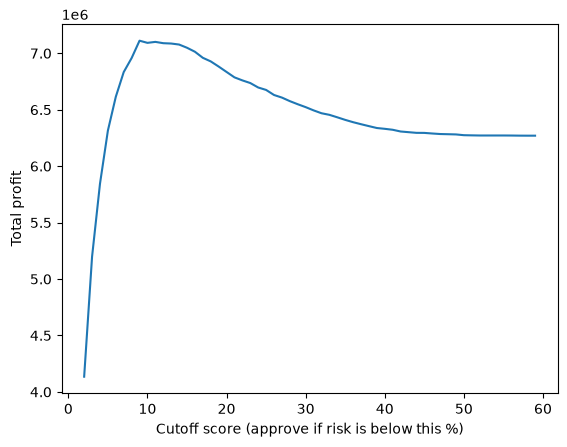

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ASSUMPTIONS: change these to match your case materials
interest_rate = 0.15
loss_rate = 1.00

prob = prob_rf          # or prob_lr
test_rows = df.loc[y_test.index]

res = pd.DataFrame({
    "prob": prob,
    "default": y_test.values,
    "balance": test_rows["bal_12m"].values,
})
res["profit"] = np.where(res["default"] == 0,
                         res["balance"] * interest_rate,
                         -res["balance"] * loss_rate)

rows = []
for cutoff in np.arange(0.02, 0.60, 0.01):
    approved = res[res["prob"] < cutoff]
    rows.append({"cutoff_%": round(cutoff * 100),
                 "approved_%": round(len(approved) / len(res) * 100, 1),
                 "default_rate_%": round(approved["default"].mean() * 100, 2),
                 "profit": round(approved["profit"].sum())})
table = pd.DataFrame(rows)

print(table.loc[table["profit"].idxmax()])
print("Profit if you approve everyone:", round(res["profit"].sum()))

plt.plot(table["cutoff_%"], table["profit"])
plt.xlabel("Cutoff score (approve if risk is below this %)")
plt.ylabel("Total profit")
plt.show()

In [11]:
rows = []
for ir in [0.10, 0.15, 0.20, 0.25]:
    for ls in [0.5, 0.8, 1.0]:
        profit = np.where(res["default"] == 0, res["balance"] * ir, -res["balance"] * ls)
        best_cut, best_profit = None, None
        for cutoff in np.arange(0.02, 0.60, 0.01):
            total = profit[res["prob"].values < cutoff].sum()
            if best_profit is None or total > best_profit:
                best_cut, best_profit = cutoff, total
        approved = (res["prob"] < best_cut).mean() * 100
        rows.append((ir, ls, round(best_cut * 100), round(approved, 1)))

print(pd.DataFrame(rows, columns=["interest", "loss", "best_cutoff_%", "approved_%"]))

    interest  loss  best_cutoff_%  approved_%
0       0.10   0.5             15        86.6
1       0.10   0.8              9        76.1
2       0.10   1.0              9        76.1
3       0.15   0.5             23        94.5
4       0.15   0.8             14        85.1
5       0.15   1.0              9        76.1
6       0.20   0.5             25        95.8
7       0.20   0.8             18        90.1
8       0.20   1.0             15        86.6
9       0.25   0.5             27        96.8
10      0.25   0.8             25        95.8
11      0.25   1.0             18        90.1


# Does the model work? Predicted vs. actual default rate.

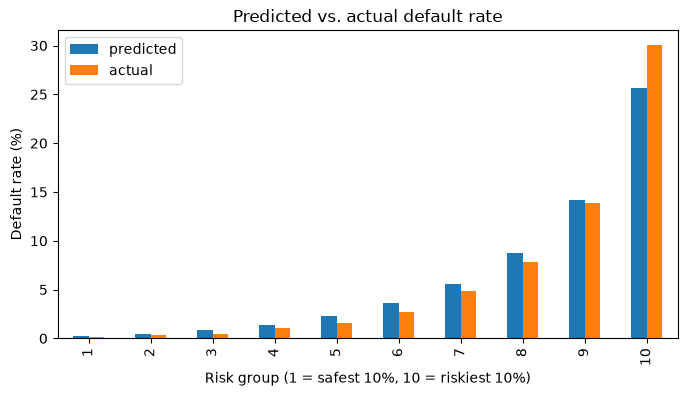

In [12]:
g = results.groupby("group", observed=True).agg(
    predicted=("risk_score_forest", "mean"),
    actual=("actual_default", lambda s: s.mean() * 100))
g.index = range(1, len(g) + 1)

g.plot(kind="bar", figsize=(8, 4))
plt.xlabel("Risk group (1 = safest 10%, 10 = riskiest 10%)")
plt.ylabel("Default rate (%)")
plt.title("Predicted vs. actual default rate")
plt.savefig("chart1_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

# What’s the best cutoff? Profit by cutoff.

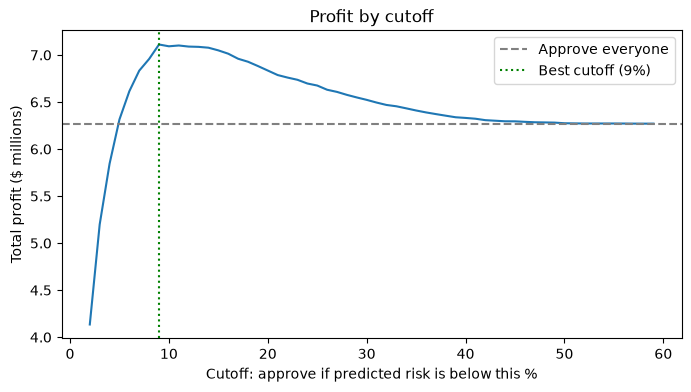

In [13]:
best = table.loc[table["profit"].idxmax()]

plt.figure(figsize=(8, 4))
plt.plot(table["cutoff_%"], table["profit"] / 1e6)
plt.axhline(res["profit"].sum() / 1e6, linestyle="--", color="gray", label="Approve everyone")
plt.axvline(best["cutoff_%"], linestyle=":", color="green", label=f"Best cutoff ({best['cutoff_%']:.0f}%)")
plt.xlabel("Cutoff: approve if predicted risk is below this %")
plt.ylabel("Total profit ($ millions)")
plt.title("Profit by cutoff")
plt.legend()
plt.savefig("chart2_profit.png", dpi=200, bbox_inches="tight")
plt.show()

# What drives default? Direction of each factor.

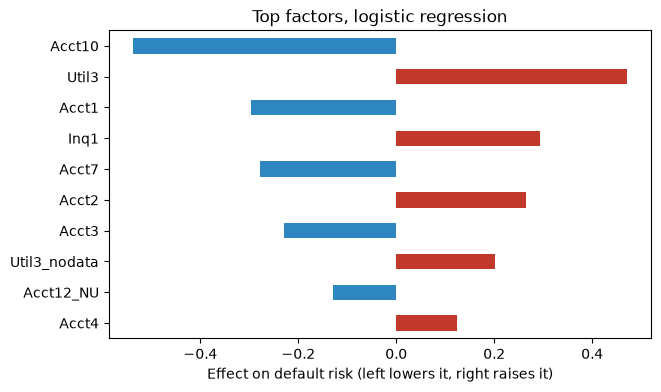

In [14]:
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)[::-1]

top.plot(kind="barh", figsize=(7, 4),
         color=["#c0392b" if v > 0 else "#2e86c1" for v in top])
plt.xlabel("Effect on default risk (left lowers it, right raises it)")
plt.title("Top factors, logistic regression")
plt.savefig("chart3_drivers.png", dpi=200, bbox_inches="tight")
plt.show()

# The no-credit-file finding.

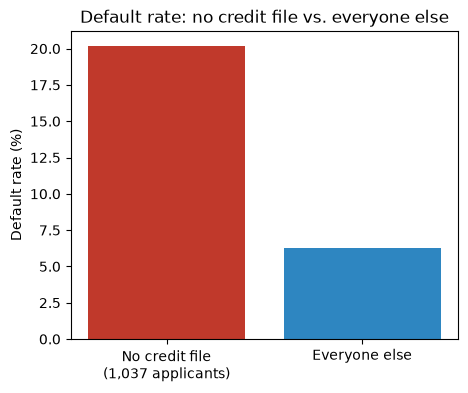

In [15]:
plt.figure(figsize=(5, 4))
plt.bar(["No credit file\n(1,037 applicants)", "Everyone else"], [20.2, 6.3],
        color=["#c0392b", "#2e86c1"])
plt.ylabel("Default rate (%)")
plt.title("Default rate: no credit file vs. everyone else")
plt.savefig("chart4_nofile.png", dpi=200, bbox_inches="tight")
plt.show()